# 02 · Synthetic Spectra

How to generate IR spectra from a list of peaks, where the true answer is known.

1. Compare the line shapes
2. Build a spectrum from a peak list
3. Add noise and a baseline

Code: `src/spectro/lineshapes.py`, `synthetic.py`.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spectro import Peak, make_spectrum, plot_spectrum

## 1. Compare the Line Shapes

A `Peak` is described by its center, FWHM and height. All three shapes below share those values; they differ in their tails. Lorentzian tails are much wider, and pseudo-Voigt (`eta=0.5`) sits in between.

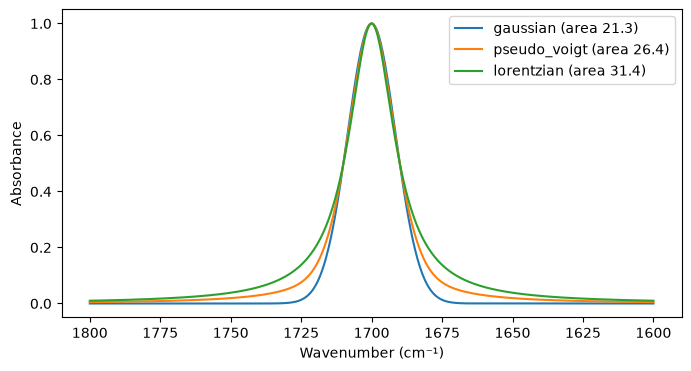

In [2]:
x = np.linspace(1600, 1800, 1000)

fig, ax = plt.subplots(figsize=(8, 4))
for shape in ["gaussian", "pseudo_voigt", "lorentzian"]:
    peak = Peak(center=1700, fwhm=20, height=1.0, shape=shape)
    ax.plot(x, peak.evaluate(x), label=f"{shape} (area {peak.area:.1f})")
ax.set_xlabel("Wavenumber (cm⁻¹)")
ax.set_ylabel("Absorbance")
ax.invert_xaxis()
ax.legend();

## 2. Build a spectrum from a peak list

`make_spectrum` adds the peaks together and returns the spectrum and a table of the true peaks. Later steps will produce tables with the same columns, so we can compare what they find against this one.

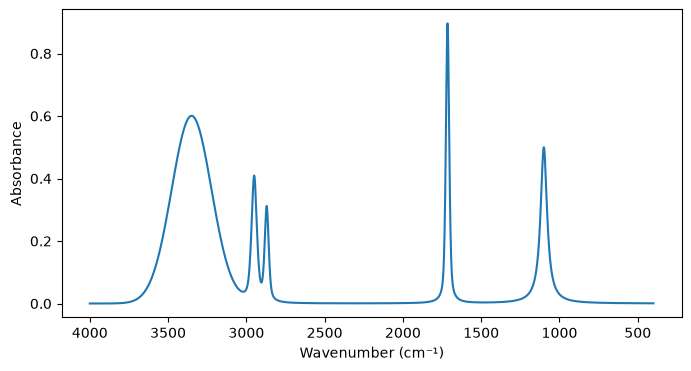

In [3]:
peaks = [
    Peak(center=3350, fwhm=300, height=0.6, shape="gaussian"),  # O–H
    Peak(center=2950, fwhm=40, height=0.4),  # C–H
    Peak(center=2870, fwhm=30, height=0.3),  # C–H
    Peak(center=1715, fwhm=25, height=0.9),  # C=O
    Peak(center=1100, fwhm=50, height=0.5, shape="lorentzian"),  # C–O
]

clean, true_peaks = make_spectrum(peaks)
plot_spectrum(clean);

In [4]:
true_peaks

,shape,center,fwhm,height,area
0,lorentzian,1100,50,0.5,39.269908
1,pseudo_voigt,1715,25,0.9,29.646713
2,pseudo_voigt,2870,30,0.3,11.858685
3,pseudo_voigt,2950,40,0.4,21.082107
4,gaussian,3350,300,0.6,191.604063


## 3. Add noise and a baseline

Real spectra have noise and a drifting background. `noise` is the standard deviation in absorbance, and `baseline` gives polynomial coefficients (offset, slope, curvature) in absorbance across the spectrum. `seed` makes the noise repeatable.

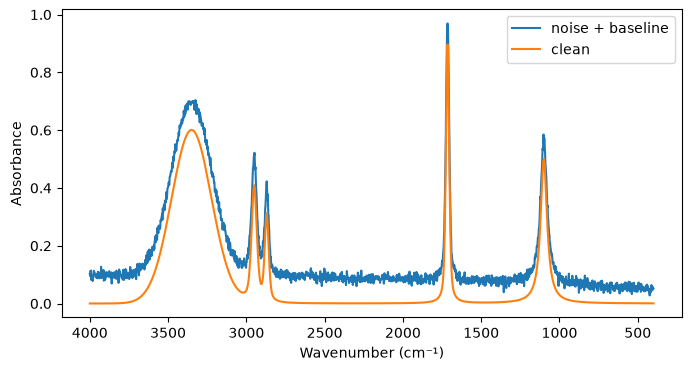

In [5]:
realistic, _ = make_spectrum(peaks, noise=0.01, baseline=(0.05, 0.1, -0.05), seed=0)

ax = plot_spectrum(realistic, label="noise + baseline")
plot_spectrum(clean, ax=ax, label="clean")
ax.legend();